In [1]:
import numpy as np

def read_spectra(file_path: str) -> tuple[np.ndarray, np.ndarray]:
    """
    Reads spectral data from a file and returns the wavelengths and intensities.

    Parameters:
    file_path (str): The path to the spectral data file.

    Returns:
    tuple: A tuple containing two numpy arrays: (wavelengths, intensities).
    """
    with open(file_path, 'r') as f:
        lines = f.readlines()
    while lines[0].strip('\n') != ">>>>>Begin Spectral Data<<<<<":
        lines.pop(0)
    lines.pop(0)  # Remove the ">>>>>Begin Spectral Data<<<<<
    wavelengths = []
    intensities = []
    for line in lines:
        parts = line.split()
        wavelengths.append(float(parts[0]))
        intensities.append(float(parts[1]))
    return np.array(wavelengths), np.array(intensities)

In [2]:
import os

filenames = os.listdir("assets/data/pt_color_08252026")
print(filenames)

['onsio2_HR4019471__0__18-21-46-403.txt', 'pt160c_HR4019471__1__18-18-23-406.txt', 'pt_HR4019471__0__18-12-59-425.txt', 'pt225c_HR4019471__0__18-15-17-408.txt', 'sio2_HR4019471__0__18-26-14-399.txt']


In [3]:
spectra = {}
for filename in filenames:
    if filename.endswith(".txt"):
        file_path = os.path.join("assets/data/pt_color_08252026", filename)
        wavelengths, intensities = read_spectra(file_path)
        spectra[filename] = (wavelengths, intensities)
print(spectra.keys())

dict_keys(['onsio2_HR4019471__0__18-21-46-403.txt', 'pt160c_HR4019471__1__18-18-23-406.txt', 'pt_HR4019471__0__18-12-59-425.txt', 'pt225c_HR4019471__0__18-15-17-408.txt', 'sio2_HR4019471__0__18-26-14-399.txt'])


In [16]:
pt225_absorp = -np.log10(np.maximum(spectra['pt225c_HR4019471__0__18-15-17-408.txt'][1] / spectra['pt_HR4019471__0__18-12-59-425.txt'][1], 1e-10))
pt160_absorp = -np.log10(np.maximum(spectra['pt160c_HR4019471__1__18-18-23-406.txt'][1] / spectra['pt_HR4019471__0__18-12-59-425.txt'][1], 1e-10))

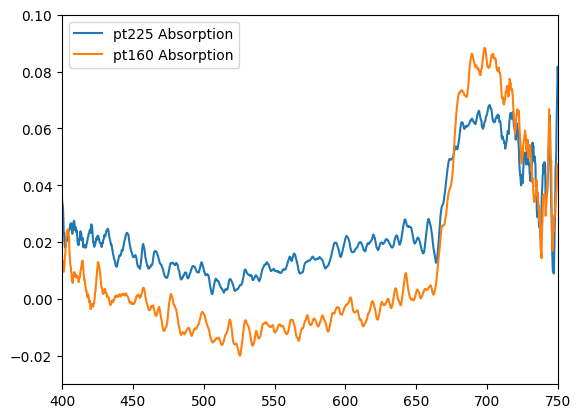

In [24]:
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter

fig, ax = plt.subplots()
x = spectra['pt225c_HR4019471__0__18-15-17-408.txt'][0]
pt225_absorp_smooth = savgol_filter(pt225_absorp, 21, 3)  # window size 11, polynomial order 3
pt160_absorp_smooth = savgol_filter(pt160_absorp, 21, 3)  # window size 11, polynomial order 3
ax.plot(x, pt225_absorp_smooth, label='pt225 Absorption')
ax.plot(x, pt160_absorp_smooth, label='pt160 Absorption')
ax.set_xlim(400, 750)
ax.set_ylim(-0.03, 0.1)
ax.legend()
fig.savefig("pt_absorption.png", dpi=600, bbox_inches='tight')

In [20]:
onsio2_absorp = -np.log10(np.maximum(spectra['onsio2_HR4019471__0__18-21-46-403.txt'][1] / spectra['sio2_HR4019471__0__18-26-14-399.txt'][1], 1e-10))

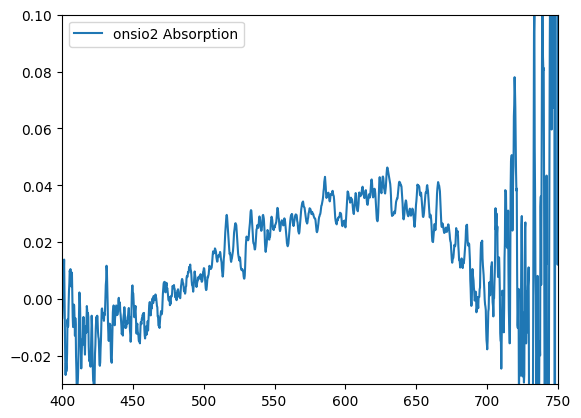

In [25]:
fig, ax = plt.subplots()
onsio2_absorp_smooth = savgol_filter(onsio2_absorp, 11, 3)  # window size 11, polynomial order 3
x_onsio2 = spectra['onsio2_HR4019471__0__18-21-46-403.txt'][0]
ax.plot(x_onsio2, onsio2_absorp_smooth, label='onsio2 Absorption')
ax.set_xlim(400, 750)
ax.set_ylim(-0.03, 0.1)
ax.legend()
fig.savefig("onsio2_absorption.png", dpi=600, bbox_inches='tight')